## The Gini coefficient, or Gini index
- It was developed by Italian statistician Corrado Gini (1884–1965) and is named after him.
- Measured in between 0 to 1, 
- 0 means less and 1 means higher
- It can be used to calculate any inequality - in income, life expectancy etc.


In [75]:
# using pairwise gap method
income_data = [0, 0, 0]

In [81]:
if np.mean(income_data) == 0:
    print("Zero")

Zero


In [76]:
# organize the data by sorting the incoming data
income_data_sorted = sorted(income_data)

In [77]:
#calculate the sum of |xi-xj|
import numpy as np
n = len(income_data_sorted)
mean_data =  np.mean(income_data_sorted)

sum = 0
for i in range(n):
    for j in range(n):
        sum += np.abs(income_data_sorted[i] -  income_data_sorted[j])

In [78]:
# normalize the result
gini = np.round(sum / (2 * n * n * mean_data), 2)
print(gini)

nan


C:\Users\Vishnu Jayan\AppData\Local\Temp\ipykernel_11284\3616109004.py:2: RuntimeWarning: invalid value encountered in scalar divide
  gini = np.round(sum / (2 * n * n * mean_data), 2)


In [5]:
# finding outliers of data
q1 = np.percentile(income_data_sorted, 25)
q3 = np.percentile(income_data_sorted, 75)
iqr =  q3 - q1

In [6]:
# Removing outliers
upper_bound = q3 + (1.5 * iqr)
lower_bound = q1 - (1.5 * iqr)
final_values = list(filter(lambda x : x < upper_bound or x > lower_bound, income_data_sorted))
print(final_values)

[10, 20, 30, 40, 50, 100]


In [9]:
import pandas as pd

In [89]:
file_path = r'..\data\data.csv'
data = pd.read_csv(file_path)
income_data = np.array(data["income"])
type(income_data)


numpy.ndarray

In [96]:
type(income_data).__module__ == np.__name__

True

In [58]:
# cumulative income calculation
income = [20, 30, 50, 80, 100]
income_data_sorted = sorted(income)
cum_income = np.cumsum(income_data_sorted)
total = np.sum(income_data_sorted)
cum_income_percentage = [np.round(item/total, 2) for item in cum_income]
cum_income_percentage.insert(0,0)
print(cum_income_percentage)

[0, np.float64(0.07), np.float64(0.18), np.float64(0.36), np.float64(0.64), np.float64(1.0)]


In [60]:
perfect_equality = np.linspace(0, 1, len(cum_income_percentage))
perfect_equality

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

In [39]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


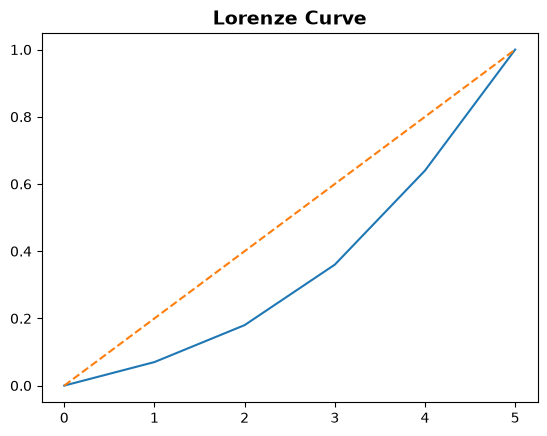

In [64]:
fig = plt.figure()
plt.plot(cum_income_percentage)
plt.plot(perfect_equality,  linestyle ='--')
plt.title('Lorenze Curve', fontsize=14, fontweight='bold')
plt.show()